**Last updated: 2026-11-10 13:42** — readout resonators and Purcell filter shortened from the HFSS calibration (readouts were 6.61-6.92 GHz, filter 7.10 GHz; now aimed at 7.3-7.7 and 7.5 GHz). New Purcell eigenmode cell (N1 as 50 ohm: filter, readout kappa, qubit Purcell T1). S11 sweep 6.5-8.5 GHz. EPR runs switched off (already done for this design).

# Five qubits + four tunable couplers: first pass

**To change the design:** edit the numbers in the *Design parameters* cell, then **Restart & Run All**.

The cells after that build the chip from those numbers. The only hand-placed layout coordinates are in the control-line routing table, and its comments say so.

Two custom components live next to this notebook: the tunable coupler in `h_coupler.py` and the floating flux line in `floating_flux.py`. `squid_cell.py` draws the SQUIDs for the GDS export, and `capacitance.py` estimated the island capacitances that the pad sizes are computed from.

Readout is in reflection through launchpad N1. The shared feedline is itself the Purcell filter, a quarter-wave resonator at the readout band.

In [1]:
import importlib
import math
import os

os.environ.setdefault("QISKIT_METAL_HEADLESS", "True")

from qiskit_metal import designs, Dict
import qiskit_metal as qm
from qiskit_metal.qlibrary.qubits.transmon_cross_fl import TransmonCrossFL
from qiskit_metal.qlibrary.couplers.coupled_line_tee import CoupledLineTee
from qiskit_metal.qlibrary.tlines.meandered import RouteMeander
from qiskit_metal.qlibrary.terminations.launchpad_wb import LaunchpadWirebond
from qiskit_metal.qlibrary.terminations.open_to_ground import OpenToGround
from qiskit_metal.qlibrary.terminations.short_to_ground import ShortToGround
from qiskit_metal.qlibrary.tlines.straight_path import RouteStraight
from qiskit_metal.qlibrary.tlines.anchored_path import RouteAnchors

from qiskit_metal.qlibrary.couplers.line_tee import LineTee

# Local files next to this notebook. A running kernel can miss a file added
# after it started, so refresh the import system's view of the folder first.
importlib.invalidate_caches()
from h_coupler import TransmonHCoupler  # local file: h_coupler.py
from floating_flux import FloatingFluxLine  # local file: floating_flux.py
from squid_cell import write_squid_library  # local file: squid_cell.py
from capacitance import capacitance_rows  # local file: capacitance.py

## Design parameters

In [ ]:
# =====================================================================
#  DESIGN PARAMETERS
#  Every number you are likely to tune lives in this cell. Edit, then
#  Restart & Run All. The suffix on each name is its unit (_um / _mm).
# =====================================================================

# --- Chip ------------------------------------------------------------
chip_size_mm = 5.0
cpw_width_um = 10  # default centre trace for every route
cpw_gap_um = 6

# --- Qubits (TransmonCrossFL) -----------------------------------------
n_qubits = 5
qubit_pitch_mm = 0.75
qubit_row_y_mm = 0.0
# Etched pocket around the cross, per arm: the length is measured from the
# edge of the central square to the arm's etched tip, the width across it.
# It is the same for every qubit. The metal arm width inside it is set per
# qubit from its frequency (see the junction cell); the gap and the metal arm
# length follow from the two.
cross_etch_arm_length_um = 215.45
cross_etch_arm_width_um = 89.1

# Readout claw on the north arm: a U of metal wrapped around the arm tip.
# Sizes are of the claw metal itself. "Length" runs along the arm,
# "width" across it. The ground spacing (claw gap to cross gap) follows
# from these and the cross sizes above.
claw_outer_length_um = 210.9
claw_outer_width_um = 128.9
claw_inner_length_um = 200
claw_inner_width_um = 107.1
claw_gap_um = 6

# XY drive pad (open-ended CPW). Inner qubits: placed beside the south arm,
# relative to the qubit centre. The two edge qubits are instead driven
# end-on through their outer arm (west for Q0, east for the last qubit),
# with this much ground between the arm's pocket tip and the line's open end.
edge_xy_pad_spacing_um = 30
xy_pad_dx_mm = -0.10
xy_pad_dy_mm = -0.18
xy_pad_width_um = 10
xy_pad_gap_um = 6
xy_pad_termination_gap_um = 6

# Flux-line T at the SQUID (used by the couplers and every qubit except the
# floating one below)
flux_t_top_um = 15
flux_t_width_um = 5
flux_t_gap_um = 3
flux_t_inductive_gap_um = 3
flux_t_offset_um = 0

# Floating flux line on the last qubit: a hairpin under the SQUID, wired
# between two launchpads, never touching ground. Trace, gap and inductive gap
# match the flux T above.
floating_flux_leg_pitch_um = 40  # centre-to-centre spacing of the two legs
floating_flux_leg_length_um = 30

# --- Tunable couplers (TransmonHCoupler, see h_coupler.py) ------------
# One I-beam coupler midway between each qubit pair, on the qubit row.
# The tip of each neighbouring qubit's etched arm pocket sits inside one of
# its slots, with a strip of ground plane all the way round between that
# pocket and the coupler's own etch.
# How far the bars reach past each qubit pocket tip. It sets most of the
# qubit-coupler coupling: 80 um gives Q-TC 3.5 fF, 25 um about 1.2-1.6 fF.
# The bar width is set per coupler from its frequency (see the junction cell).
coupler_insertion_um = 30
coupler_ground_strip_um = 5  # ground between qubit pocket and coupler etch
coupler_web_width_um = 30  # vertical web joining the bars
coupler_pocket_gap_um = 15  # coupler metal to ground plane
coupler_jj_width_um = 20

# --- Josephson junctions --------------------------------------------
# Every qubit and coupler has a symmetric SQUID: two identical Dolan-bridge
# junctions in parallel. Each junction is drawn like the reference cell: a
# 2 um lead tapering to a finger 1.36 um long that stops 0.15 um short of the
# other electrode. All qubits share one finger width and all couplers another.
# Junction area = finger width x overlap. The overlap comes from the bridge
# height and evaporation angles, not the layout, so it is an input here.
jj_jc_ua_per_um2 = 0.5  # critical current density
jj_overlap_um = 0.20  # ASSUMED: put in your process's measured overlap
jj_reference_finger_width_um = 0.42  # the reference cell, for comparison
# Maximum (zero-flux) frequencies; flux tunes each element down from here.
# With one junction size per element type, each frequency is set by the pad
# capacitance (C_sigma), which the junction cell sizes from these.
qubit_freqs_ghz = [4.500, 4.625, 4.750, 4.875, 5.000]  # Q0..Q4, 125 MHz apart
coupler_freqs_ghz = [5.50, 5.83, 6.17, 6.50]  # TC0..TC3, ~333 MHz apart, well below readout
# The shared junction of each type is sized so the element in the middle of
# its list has this anharmonicity, as HFSS + EPR will see it. Higher-frequency
# elements (smaller pads) get more. Neighbouring qubits sit about half an
# anharmonicity apart: as far as possible from both |01>-|10> (detuning 0)
# and |11>-|02> (detuning = anharmonicity). 250 MHz keeps E_J/E_C ~ 64.
qubit_target_anharmonicity_mhz = 250
coupler_target_anharmonicity_mhz = 200
# Tunnel-barrier capacitance per unit junction area. It adds to C_sigma, so
# it comes off each pad's share. Not measured yet: 0 leaves it out.
jj_specific_capacitance_ff_per_um2 = 0
# C_sigma vs pad size, from capacitance.py on this layout. The junction cell
# interpolates these to size each pad. Qubit C_sigma barely depends on the
# coupler size or on edge vs inner position (< 0.3 fF), and coupler C_sigma
# barely on the qubit arms (< 1 fF). After changing the etched pockets, claws
# or pitch, re-measure: set run_capacitance_check = True and compare.
qubit_csigma_vs_arm_width_ff = {
    5: 66.1, 7.5: 72.9, 10: 78.9, 15: 90.9, 20: 101.6, 30: 121.1, 45: 152.5, 60: 191.1,
}
# Couplers: bar width, measured at coupler_insertion_um = 30. Re-measure if
# the insertion changes.
coupler_csigma_vs_bar_width_ff = {5: 74.6, 10: 89.6, 20: 104.8, 30: 118.3, 45: 134.1}
# Calibration against HFSS (project five_plus_four_hfss_5, 2026-11-09). The
# frequencies HFSS gave, at the L_J it was given, imply a C_sigma 12 % (qubits)
# and 14 % (couplers) above these tables, the same at every pad size. And EPR
# gives an anharmonicity 4 % below the plain transmon one at that C_sigma
# (the junction holds ~98 % of each mode's inductive energy, not all of it).
qubit_csigma_hfss_factor = 1.12
coupler_csigma_hfss_factor = 1.14
anharmonicity_hfss_factor = 0.96
run_capacitance_check = True  # a minute or two

# --- Readout --------------------------------------------------------------
# Target bare quarter-wave frequencies, Q0..Q4. The meander lengths are
# computed from these (see the resonator cell), so edit frequencies, not lengths.
resonator_freqs_ghz = [7.3, 7.4, 7.5, 7.6, 7.7]
# HFSS calibration of the resonator lengths. With the lengths computed for
# 7.3-7.7 GHz from (eps_r + 1) / 2 alone, HFSS (full_chip, 2026-11-10) gave
# these frequencies, about 10 % low: the claw and tee capacitances load each
# resonator, and the real effective permittivity differs a little. 1/f_HFSS
# is a straight line in 1/f_design (to 1.3 MHz here), and the resonator
# cell inverts that line to choose each length. Lengths are computed for
# 7.3 -> 6.607 etc., not frequencies the chip had. Replace with new HFSS
# numbers and the lengths they were computed for, to refine.
resonator_hfss_calibration_ghz = {7.3: 6.607, 7.4: 6.684, 7.5: 6.763, 7.6: 6.843, 7.7: 6.921}
substrate_eps_r = 11.45  # silicon at cryogenic temperature
resonator_meander_spacing_um = 50
resonator_lead_um = 150  # straight section at each end of the meander
resonator_fillet_um = 20

# Purcell filter: the shared feedline is itself a quarter-wave resonator at
# the readout band, so readout photons get out and the far-detuned qubits
# are blocked. Read out in reflection from N1. The line starts at its west
# end, where N1 drops onto it and a short stub runs to ground; the stub's
# length sets the filter Q (bandwidth = freq / Q). The line then runs east
# through every tee and ends open past the last one, folding up and back
# west only if it is too long to fit before purcell_fold_x_mm.
purcell_filter_freq_ghz = 7.5
purcell_filter_q = 15  # 500 MHz bandwidth, covering the readout band
# HFSS calibration of the filter length: built for 7.5 GHz from (eps_r + 1)/2,
# the driven S11 run (2026-11-10) put the filter at 7.10 GHz. The tees load
# the line. Update from the eigenmode run's PurcellFilter mode:
# new factor = old factor * f_HFSS / purcell_filter_freq_ghz.
purcell_filter_hfss_factor = 7.10 / 7.5
feedline_y_mm = 1.5
purcell_short_x_mm = -1.80  # the short stub runs west to here, then up to ground
purcell_fold_x_mm = 1.70  # east end of the feedline turns north here...
purcell_fold_y_mm = 1.75  # ...and runs back west at this height to the open end
tee_coupling_length_um = 200
tee_coupling_space_um = 4

# --- GDS export -----------------------------------------------------
# Written next to this notebook by the last cells. The base metal is layer 1;
# each Metal junction line is replaced by a SQUID cell on jj_layer (see
# squid_cell.py), built from the reference junction with this notebook's
# finger widths.
gds_file = "five_plus_four.gds"
junction_gds_file = "squids.gds"  # the SQUID cells, also usable on their own
jj_layer = 2

# --- Launchpads -------------------------------------------------------
pad_inset_mm = 2.2  # pad centre distance from chip centre
ns_pad_offsets_mm = [-1.625, -0.975, -0.325, 0.325, 0.975, 1.625]  # N & S edges
ew_pad_offsets_mm = [-1.6, -0.6, 0.4, 1.4]  # E & W edges

# --- Routing --------------------------------------------------------
control_line_fillet_um = 50
feedline_fillet_um = 50

# --- HFSS simulations -------------------------------------------------
# Run in Ansys HFSS through Metal's "hfss" renderer, which starts AEDT if it
# is not already open. Each takes from minutes to an hour or more, so they are
# all off by default. Every junction is a lumped inductor at its element's
# zero-flux L_J from the junction cell, so the results are at maximum frequency.
run_hfss_qubit_epr = False  # eigenmode + EPR: a qubit, its readout and couplers
hfss_epr_qubits = list(range(n_qubits))  # which qubits, e.g. [2] for just Q2
run_hfss_coupler_epr = False  # eigenmode + EPR: two qubits, the coupler, readouts
hfss_epr_couplers = list(range(n_qubits - 1))  # which couplers, e.g. [1] for just TC1
run_hfss_full_epr = False  # eigenmode + EPR: every qubit, coupler and readout at once (hours)
# eigenmode, N1 as a 50 ohm resistor: frequency and Q of every qubit, readout
# and the filter itself, so readout kappa and Purcell-limited qubit T1
run_hfss_purcell_eigenmode = True
run_hfss_purcell = True  # driven modal: S11 at N1 through the Purcell filter
hfss_purcell_sweep_ghz = (6.5, 8.5, 4001)  # start, stop, points (0.5 MHz steps)
hfss_max_passes = 20
hfss_basis_order = -1  # 0 zero, 1 first, 2 second, -1 mixed
hfss_max_delta_f = 0.1  # eigenmode convergence, % change in frequency per pass
hfss_min_converged = 2  # passes in a row that must meet it before HFSS stops
hfss_max_delta_s = 0.02  # driven-modal convergence, change in S per pass
hfss_buffer_mm = 0.3  # substrate and vacuum beyond what is rendered
hfss_project_file = "five_plus_four_hfss.aedt"  # new each run; _2, _3... if taken
hfss_results_dir = "hfss_results"  # every run's mode table and chi matrix, as CSV

## Josephson junctions

In [3]:
# One junction size for all qubits and one for all couplers; each element's
# frequency then comes from its pad capacitance.
#   1. E_J: the element in the middle of the frequency list gets its type's
#      target anharmonicity.
#   2. Each element's E_C (so C_sigma) puts it at its own frequency.
#   3. Each pad is sized from the C_sigma tables in the parameters.
# C_sigma and the anharmonicity are what HFSS + EPR will see: the tables are
# scaled by the HFSS factors in the parameters, and the plain transmon
# anharmonicity is aimed above the target by anharmonicity_hfss_factor.
# Levels come from the transmon Hamiltonian 4 E_C (n - n_g)^2 - E_J cos(phi),
# solved in the charge basis. At zero flux a symmetric SQUID is one junction
# with the I_c of both halves. E_C/h = e^2 / (2 h C), E_J/h = I_c Phi_0 / (2 pi h).
import numpy as np
from scipy.optimize import brentq

EC_GHZ_FF = 19.37  # e^2 / 2h, in GHz * fF
EJ_GHZ_PER_UA = 496.7  # Phi_0 / (2 pi h), in GHz per uA
PHI0_2PI_NH_UA = 0.3291  # Phi_0 / 2 pi, in nH * uA


def transmon_levels(ej_ghz, ec_ghz, ng=0.25, n_cut=30):
    """f01 and anharmonicity f12 - f01, in GHz. n_g = 0.25 sits mid-way in
    the charge dispersion, which is negligible at these E_J/E_C."""
    n = np.arange(-n_cut, n_cut + 1)
    h = np.diag(4 * ec_ghz * (n - ng) ** 2)
    h -= ej_ghz / 2 * (np.eye(n.size, k=1) + np.eye(n.size, k=-1))
    e = np.linalg.eigvalsh(h)
    return e[1] - e[0], e[2] - 2 * e[1] + e[0]


def ec_for(ej_ghz, freq_ghz):
    return brentq(lambda ec: transmon_levels(ej_ghz, ec)[0] - freq_ghz, 1e-3, 5.0)


def junction_set(prefix, freqs_ghz, alpha_mhz):
    """Shared SQUID for one element type, and each element's C_sigma."""
    f_mid = (min(freqs_ghz) + max(freqs_ghz)) / 2
    alpha_ghz = -alpha_mhz / anharmonicity_hfss_factor / 1e3
    ej_ghz = brentq(
        lambda ej: transmon_levels(ej, ec_for(ej, f_mid))[1] - alpha_ghz, 10, 300
    )
    ic_ua = ej_ghz / EJ_GHZ_PER_UA  # whole SQUID
    area_um2 = ic_ua / 2 / jj_jc_ua_per_um2  # each of its two junctions
    cj_ff = 2 * area_um2 * jj_specific_capacitance_ff_per_um2
    out = {}
    for i, f in enumerate(freqs_ghz):
        ec_ghz = ec_for(ej_ghz, f)
        out[f"{prefix}{i}"] = dict(
            freq_ghz=f,
            ec_mhz=ec_ghz * 1e3,
            alpha_mhz=transmon_levels(ej_ghz, ec_ghz)[1] * 1e3 * anharmonicity_hfss_factor,
            ej_ghz=ej_ghz,
            csigma_ff=EC_GHZ_FF / ec_ghz,
            pad_csigma_ff=EC_GHZ_FF / ec_ghz - cj_ff,
            cj_ff=cj_ff,
            ic_na=ic_ua * 1e3,
            lj_nh=PHI0_2PI_NH_UA / ic_ua,
            area_um2=area_um2,
            finger_um=area_um2 / jj_overlap_um,
        )
    return out


squids = junction_set("Q", qubit_freqs_ghz, qubit_target_anharmonicity_mhz)
squids.update(junction_set("TC", coupler_freqs_ghz, coupler_target_anharmonicity_mhz))


def size_from_table(target_ff, table, name):
    """Pad size giving target_ff, by linear interpolation in the table."""
    sizes = sorted(table)
    caps = [table[s] for s in sizes]
    if not caps[0] <= target_ff <= caps[-1]:
        print(f"  WARNING: {name} needs {target_ff:.1f} fF, outside the measured "
              f"{caps[0]:.1f}-{caps[-1]:.1f} fF; its pad size is extrapolated.")
        i = 0 if target_ff < caps[0] else len(sizes) - 2
        s0, s1, c0, c1 = sizes[i], sizes[i + 1], caps[i], caps[i + 1]
        return s0 + (target_ff - c0) * (s1 - s0) / (c1 - c0)
    return float(np.interp(target_ff, caps, sizes))


# Qubits: metal arm width inside the fixed etched pocket.
for i in range(n_qubits):
    s = squids[f"Q{i}"]
    s["pad_um"] = size_from_table(
        s["pad_csigma_ff"], {k: v * qubit_csigma_hfss_factor for k, v in
                             qubit_csigma_vs_arm_width_ff.items()}, f"Q{i}")
qubit_arm_widths_um = [squids[f"Q{i}"]["pad_um"] for i in range(n_qubits)]

# Couplers: bar width.
for i in range(n_qubits - 1):
    s = squids[f"TC{i}"]
    s["pad_um"] = size_from_table(
        s["pad_csigma_ff"], {k: v * coupler_csigma_hfss_factor for k, v in
                             coupler_csigma_vs_bar_width_ff.items()}, f"TC{i}")
coupler_bar_widths_um = [squids[f"TC{i}"]["pad_um"] for i in range(n_qubits - 1)]

print(f"Jc {jj_jc_ua_per_um2} uA/um^2, overlap {jj_overlap_um} um, "
      f"reference finger {jj_reference_finger_width_um} um")
for kind, first in (("Qubits", "Q0"), ("Couplers", "TC0")):
    s = squids[first]
    print(f"{kind}: one SQUID, E_J {s['ej_ghz']:.2f} GHz, Ic {s['ic_na']:.1f} nA, "
          f"L_J {s['lj_nh']:.2f} nH; per junction {s['area_um2']:.4f} um^2, "
          f"finger {s['finger_um']:.3f} um, C_j (both) {s['cj_ff']:.1f} fF")
    if s["finger_um"] < 0.1:
        print(f"  WARNING: {kind.lower()} need a finger under 100 nm.")
print("        f_max   E_C   alpha  E_J/E_C  C_sigma   pad      (alpha, C_sigma: as HFSS sees them)")
print("        (GHz)  (MHz)  (MHz)           (fF)     (um)")
for name, s in squids.items():
    pad = "arm width" if name.startswith("Q") else "bar width"
    print(f"  {name:<5} {s['freq_ghz']:5.2f} {s['ec_mhz']:6.0f} {s['alpha_mhz']:6.0f}"
          f" {s['ej_ghz'] / s['ec_mhz'] * 1e3:7.0f}  {s['csigma_ff']:7.1f}"
          f"   {s['pad_um']:5.1f} {pad}")

Jc 0.5 uA/um^2, overlap 0.2 um, reference finger 0.42 um
Qubits: one SQUID, E_J 17.10 GHz, Ic 34.4 nA, L_J 9.56 nH; per junction 0.0344 um^2, finger 0.172 um, C_j (both) 0.0 fF
Couplers: one SQUID, E_J 25.84 GHz, Ic 52.0 nA, L_J 6.33 nH; per junction 0.0520 um^2, finger 0.260 um, C_j (both) 0.0 fF
        f_max   E_C   alpha  E_J/E_C  C_sigma   pad
        (GHz)  (MHz)  (MHz)           (fF)     (um)
  Q0     4.50    159   -174     108    121.8    30.3 arm width
  Q1     4.65    170   -187     100    113.7    26.2 arm width
  Q2     4.80    182   -200      94    106.5    22.5 arm width
  Q3     4.95    194   -214      88     99.8    19.3 arm width
  Q4     5.10    207   -229      83     93.8    16.6 arm width
  TC0    5.50    155   -166     167    125.0    34.7 bar width
  TC1    5.83    175   -188     148    110.8    24.3 bar width
  TC2    6.17    197   -212     131     98.6    15.4 bar width
  TC3    6.50    219   -238     118     88.5     8.0 bar width


## Qubits and tunable couplers

In [4]:
design = designs.DesignPlanar()
design.chips.main.size.size_x = f"{chip_size_mm}mm"
design.chips.main.size.size_y = f"{chip_size_mm}mm"
design.variables.cpw_width = f"{cpw_width_um}um"
design.variables.cpw_gap = f"{cpw_gap_um}um"
design.overwrite_enabled = True

flux_t_options = dict(
    t_top=f"{flux_t_top_um}um",
    t_width=f"{flux_t_width_um}um",
    t_gap=f"{flux_t_gap_um}um",
    t_inductive_gap=f"{flux_t_inductive_gap_um}um",
    t_offset=f"{flux_t_offset_um}um",
)


# The etched pocket is the same for every qubit; the metal arm inside it
# varies. Gap and metal arm length (centre to tip) for a given arm width:
def cross_gap_and_length(arm_width_um):
    gap_um = (cross_etch_arm_width_um - arm_width_um) / 2
    return gap_um, cross_etch_arm_width_um / 2 + cross_etch_arm_length_um - gap_um


pocket_tip_um = cross_etch_arm_width_um / 2 + cross_etch_arm_length_um  # centre to etched arm tip

# Claw metal thicknesses and the ground spacing, from the outer/inner sizes.
claw_side_um = (claw_outer_width_um - claw_inner_width_um) / 2
claw_back_um = claw_outer_length_um - claw_inner_length_um
claw_ground_spacing_um = (claw_inner_width_um - cross_etch_arm_width_um) / 2 - claw_gap_um
if claw_ground_spacing_um < 0:
    print(
        f"WARNING: claw inner width {claw_inner_width_um} um is too narrow for the "
        f"{cross_etch_arm_width_um} um arm pocket plus the claw gap. Ground spacing = "
        f"{claw_ground_spacing_um:.2f} um: the claw overlaps the pocket."
    )
# Distance from qubit centre to the claw finger tips, vs. the E/W arm pocket.
claw_tip_um = pocket_tip_um + claw_ground_spacing_um + claw_gap_um - claw_inner_length_um
if claw_tip_um - claw_gap_um < cross_etch_arm_width_um / 2:
    print(
        f"WARNING: claw fingers reach {claw_tip_um:.1f} um from the qubit centre and "
        f"run into the E/W arm pocket (edge at {cross_etch_arm_width_um / 2} um)."
    )


def qubit_x(i):
    """x position (mm) of qubit i, centred on the chip."""
    return (i - (n_qubits - 1) / 2) * qubit_pitch_mm


floating_flux_qubit = n_qubits - 1  # routed to two pads in the control-line table

qubits, xy_pads = [], []
for i in range(n_qubits):
    x_pos = qubit_x(i)
    floating = i == floating_flux_qubit
    arm_width_um = qubit_arm_widths_um[i]
    cross_gap_um, cross_length_um = cross_gap_and_length(arm_width_um)
    qubits.append(
        TransmonCrossFL(
            design,
            f"Q{i}",
            options=dict(
                pos_x=f"{x_pos}mm",
                pos_y=f"{qubit_row_y_mm}mm",
                orientation="0",
                cross_width=f"{arm_width_um}um",
                cross_length=f"{cross_length_um}um",
                cross_gap=f"{cross_gap_um}um",
                make_fl=not floating,
                gds_cell_name=f"SQUID_Q{i}",  # see the GDS export cell
                fl_options=flux_t_options,
                connection_pads=dict(
                    readout=dict(
                        connector_type="0",
                        claw_length=f"{claw_inner_length_um}um",
                        claw_width=f"{claw_side_um}um",
                        claw_width_back=f"{claw_back_um}um",
                        ground_spacing=f"{claw_ground_spacing_um}um",
                        claw_gap=f"{claw_gap_um}um",
                        connector_location="90",
                    )
                ),
            ),
        )
    )
    if floating:
        FloatingFluxLine(
            design,
            f"Q{i}_floating_flux",
            options=dict(
                pos_x=f"{x_pos}mm",
                pos_y=f"{qubit_row_y_mm - pocket_tip_um / 1e3}mm",  # under the SQUID
                width=f"{flux_t_width_um}um",
                gap=f"{flux_t_gap_um}um",
                inductive_gap=f"{flux_t_inductive_gap_um}um",
                leg_pitch=f"{floating_flux_leg_pitch_um}um",
                leg_length=f"{floating_flux_leg_length_um}um",
            ),
        )
    if i in (0, n_qubits - 1):
        # Edge qubit: open end faces the outer arm tip, line leaves sideways
        side = -1 if i == 0 else 1
        reach_um = pocket_tip_um + edge_xy_pad_spacing_um + xy_pad_termination_gap_um
        xy_x, xy_y = x_pos + side * reach_um / 1e3, qubit_row_y_mm
        xy_orient = "0" if i == 0 else "180"
    else:
        xy_x, xy_y = x_pos + xy_pad_dx_mm, qubit_row_y_mm + xy_pad_dy_mm
        xy_orient = "90"
    xy_pads.append(
        OpenToGround(
            design,
            f"XY_pad_{i}",
            options=dict(
                pos_x=f"{xy_x}mm",
                pos_y=f"{xy_y}mm",
                orientation=xy_orient,
                width=f"{xy_pad_width_um}um",
                gap=f"{xy_pad_gap_um}um",
                termination_gap=f"{xy_pad_termination_gap_um}um",
            ),
        )
    )

print(f"Design initialized on a {chip_size_mm} x {chip_size_mm} mm chip.")
print(f"Placed qubits Q0-Q{n_qubits - 1} and their XY coupling pads.")
print("  arm widths " + ", ".join(f"Q{i} {w:.1f}" for i, w in enumerate(qubit_arm_widths_um)) + " um")
print(f"  Q{floating_flux_qubit} has the floating flux line.")

Design initialized on a 5.0 x 5.0 mm chip.
Placed qubits Q0-Q4 and their XY coupling pads.
  arm widths Q0 30.3, Q1 26.2, Q2 22.5, Q3 19.3, Q4 16.6 um
  Q4 has the floating flux line.


In [5]:
# Coupler geometry follows from the qubit pockets and the coupler knobs, so
# changing the qubit pitch or etch size keeps each pocket tip centred in its
# slot with at least the ground strip around it (more in front of the tip
# when the web is narrower than the room available).
pocket_tip_from_coupler_um = (
    qubit_pitch_mm * 1e3 / 2 - cross_etch_arm_width_um / 2 - cross_etch_arm_length_um
)
coupler_clearance_um = coupler_ground_strip_um + coupler_pocket_gap_um
coupler_bar_length_um = 2 * (pocket_tip_from_coupler_um + coupler_insertion_um)
coupler_slot_height_um = cross_etch_arm_width_um + 2 * coupler_clearance_um
# The web's etch must leave at least the ground strip before each pocket tip
web_room_um = 2 * (pocket_tip_from_coupler_um - coupler_clearance_um)
assert coupler_web_width_um <= web_room_um, (
    f"coupler_web_width_um = {coupler_web_width_um} um does not fit between the "
    f"neighbouring qubit pockets (room for {web_room_um:.0f} um): narrow the web, "
    "reduce coupler_ground_strip_um / coupler_pocket_gap_um, or widen qubit_pitch_mm."
)

tunable_couplers = []
for i in range(n_qubits - 1):
    tunable_couplers.append(
        TransmonHCoupler(
            design,
            f"TC{i}",
            options=dict(
                pos_x=f"{(qubit_x(i) + qubit_x(i + 1)) / 2}mm",
                pos_y=f"{qubit_row_y_mm}mm",
                orientation="0",
                bar_length=f"{coupler_bar_length_um}um",
                bar_width=f"{coupler_bar_widths_um[i]}um",
                slot_height=f"{coupler_slot_height_um}um",
                web_width=f"{coupler_web_width_um}um",
                pocket_gap=f"{coupler_pocket_gap_um}um",
                jj_width=f"{coupler_jj_width_um}um",
                make_fl=True,
                gds_cell_name=f"SQUID_TC{i}",  # see the GDS export cell
                fl_options=flux_t_options,
            ),
        )
    )

print(f"Placed tunable couplers TC0-TC{n_qubits - 2} between the qubits.")
print(
    f"  coupler bars {coupler_bar_length_um:.0f} um long, web "
    f"{coupler_web_width_um:.0f} um, slot {coupler_slot_height_um:.0f} um tall"
)
print("  bar widths " + ", ".join(f"TC{i} {w:.1f}" for i, w in enumerate(coupler_bar_widths_um)) + " um")

Placed tunable couplers TC0-TC3 between the qubits.
  coupler bars 290 um long, web 30 um, slot 129 um tall
  bar widths TC0 34.7, TC1 24.3, TC2 15.4, TC3 8.0 um


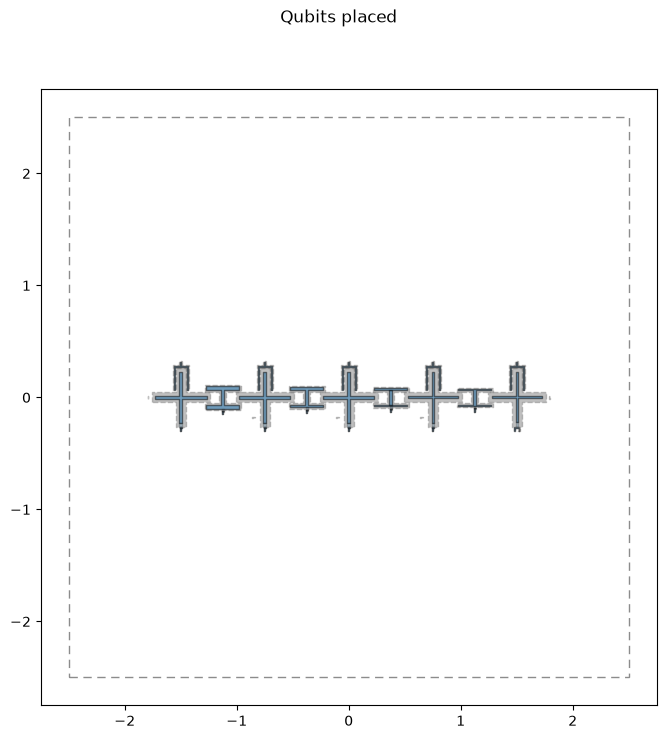

In [6]:
fig = qm.view(design)
fig.suptitle("Qubits placed")
fig

## Readout and feedline

In [7]:
# Each tee is shifted so its coupled-line end sits directly above the
# qubit's claw, keeping every resonator a straight vertical meander. Tees on
# the west half are mirrored (coupled end on their west side), which keeps
# the row of tees symmetric about the chip centre.
readout_tees = []
for i in range(n_qubits):
    mirror = i < (n_qubits - 1) / 2
    shift_mm = (1 if mirror else -1) * tee_coupling_length_um / 2e3
    readout_tees.append(
        CoupledLineTee(
            design,
            f"CLT{i}",
            options=dict(
                pos_x=f"{qubit_x(i) + shift_mm}mm",
                pos_y=f"{feedline_y_mm}mm",
                orientation="0",
                coupling_length=f"{tee_coupling_length_um}um",
                coupling_space=f"{tee_coupling_space_um}um",
                mirror=mirror,
                # Short the resonator end to ground: with the open claw at
                # the qubit, each readout resonator is a quarter-wave.
                open_termination=False,
            ),
        )
    )

# Wirebond launchpads. Numbered west->east (N/S edges), south->north (E/W).
pad_edges = {
    "W": (ew_pad_offsets_mm, lambda p: (-pad_inset_mm, p, "0")),
    "E": (ew_pad_offsets_mm, lambda p: (pad_inset_mm, p, "180")),
    "S": (ns_pad_offsets_mm, lambda p: (p, -pad_inset_mm, "90")),
    "N": (ns_pad_offsets_mm, lambda p: (p, pad_inset_mm, "270")),
}
for edge, (offsets, place) in pad_edges.items():
    for n, offset in enumerate(offsets, start=1):
        x, y, orient = place(offset)
        LaunchpadWirebond(
            design,
            f"LP_{edge}{n}",
            options=dict(pos_x=f"{x}mm", pos_y=f"{y}mm", orientation=orient),
        )

print("Placed readout tees and launchpads.")

Placed readout tees and launchpads.


In [8]:
# Purcell-filter feedline, west to east:
#   ground <- short stub <- N1 input tap -> tees -> (fold) -> open end
# The stub length comes from purcell_filter_q, and the open end's position is
# solved so the whole line (stub included) is a quarter wave at
# purcell_filter_freq_ghz.

c_mm_ghz = 299.792458
eps_eff = (substrate_eps_r + 1) / 2
# Built for the frequency that HFSS puts at purcell_filter_freq_ghz
purcell_design_freq_ghz = purcell_filter_freq_ghz / purcell_filter_hfss_factor
purcell_target_mm = c_mm_ghz / (4 * purcell_design_freq_ghz * eps_eff**0.5)
# Tapped quarter wave: Q = pi / (4 sin^2(pi/2 * tap_distance / length))
tap_from_short_mm = (
    2 * purcell_target_mm / math.pi * math.asin(math.sqrt(math.pi / (4 * purcell_filter_q)))
)


def pin_xy(component, pin):
    return design.components[component].pins[pin].middle


# Input tap butted against the west end of the first tee
tap_half_mm = 0.025
tap_x = pin_xy("CLT0", "prime_start")[0] - tap_half_mm
LineTee(
    design,
    "Purcell_tap",
    options=dict(
        pos_x=f"{tap_x}mm",
        pos_y=f"{feedline_y_mm}mm",
        orientation="180",  # input arm points north; prime_start faces east
        t_length=f"{tap_half_mm * 1e3}um",
    ),
)

pad_x, _ = pin_xy("LP_N1", "tie")
feed_in_pins = dict(
    start_pin=dict(component="LP_N1", pin="tie"),
    end_pin=dict(component="Purcell_tap", pin="second_end"),
)
if abs(pad_x - tap_x) < 1e-6:
    RouteStraight(design, "Feed_in", options=dict(pin_inputs=feed_in_pins))
else:  # N1 not directly above the tap: jog across halfway down
    mid_y = (feedline_y_mm + pin_xy("LP_N1", "tie")[1]) / 2
    RouteAnchors(
        design,
        "Feed_in",
        options=dict(
            pin_inputs=feed_in_pins,
            anchors=Dict({0: (pad_x, mid_y), 1: (tap_x, mid_y)}),
            fillet=f"{feedline_fillet_um}um",
            advanced=Dict(avoid_collision=False),
        ),
    )

# Short stub: west from the tap to purcell_short_x_mm, then up into ground.
# The trace simply ends in the ground plane at Purcell_short.
stub_mm = tap_from_short_mm - tap_half_mm
short_y = feedline_y_mm + stub_mm - (tap_x - tap_half_mm - purcell_short_x_mm)
purcell_short = ShortToGround(
    design,
    "Purcell_short",
    options=dict(pos_x=f"{purcell_short_x_mm}mm", pos_y=f"{short_y}mm", orientation="90"),
)
purcell_stub = RouteAnchors(
    design,
    "Purcell_stub",
    options=dict(
        pin_inputs=dict(
            start_pin=dict(component="Purcell_tap", pin="prime_end"),
            end_pin=dict(component="Purcell_short", pin="short"),
        ),
        anchors=Dict({0: (purcell_short_x_mm, feedline_y_mm)}),
        fillet=f"{feedline_fillet_um}um",
        advanced=Dict(avoid_collision=False),
    ),
)
short_y += stub_mm - purcell_stub.length  # absorb what the fillet takes off
purcell_short.options.pos_y = f"{short_y}mm"
purcell_short.rebuild()
purcell_stub.rebuild()

feed_mids = [
    RouteStraight(
        design,
        f"Feed_mid_{i}",
        options=dict(
            pin_inputs=dict(
                start_pin=dict(component=f"CLT{i}", pin="prime_end"),
                end_pin=dict(component=f"CLT{i + 1}", pin="prime_start"),
            )
        ),
    )
    for i in range(n_qubits - 1)
]

# Everything but the folded tail
fixed_mm = (
    purcell_stub.length
    + 2 * tap_half_mm
    + n_qubits * 2 * tee_coupling_length_um / 1e3
    + sum(f.length for f in feed_mids)
)
tail_mm = purcell_target_mm - fixed_mm

end_x0 = pin_xy(f"CLT{n_qubits - 1}", "prime_end")[0]
fold_run_mm = (purcell_fold_x_mm - end_x0) + (purcell_fold_y_mm - feedline_y_mm)
assert tail_mm > 0, (
    f"The feedline is already {-tail_mm * 1e3:.0f} um longer than a quarter wave at "
    "the last tee: lower purcell_filter_freq_ghz, raise purcell_filter_q (a "
    "shorter stub), or reduce qubit_pitch_mm."
)
if tail_mm < fold_run_mm:
    # Short tail: the line just runs on east past the last tee and ends open
    open_x = end_x0 + tail_mm
    purcell_open = OpenToGround(
        design,
        "Purcell_open",
        options=dict(pos_x=f"{open_x}mm", pos_y=f"{feedline_y_mm}mm", orientation="0"),
    )
    purcell_tail = RouteStraight(
        design,
        "Purcell_tail",
        options=dict(
            pin_inputs=dict(
                start_pin=dict(component=f"CLT{n_qubits - 1}", pin="prime_end"),
                end_pin=dict(component="Purcell_open", pin="open"),
            )
        ),
    )
else:
    # Long tail: fold north and run back west. The open end is placed, then
    # nudged once to absorb the length the fillets take off the corners.
    open_x = purcell_fold_x_mm - (tail_mm - fold_run_mm)
    purcell_open = OpenToGround(
        design,
        "Purcell_open",
        options=dict(pos_x=f"{open_x}mm", pos_y=f"{purcell_fold_y_mm}mm", orientation="180"),
    )
    purcell_tail = RouteAnchors(
        design,
        "Purcell_tail",
        options=dict(
            pin_inputs=dict(
                start_pin=dict(component=f"CLT{n_qubits - 1}", pin="prime_end"),
                end_pin=dict(component="Purcell_open", pin="open"),
            ),
            anchors=Dict({0: (purcell_fold_x_mm, feedline_y_mm),
                          1: (purcell_fold_x_mm, purcell_fold_y_mm)}),
            fillet=f"{feedline_fillet_um}um",
            advanced=Dict(avoid_collision=False),
        ),
    )
    open_x -= tail_mm - purcell_tail.length
    purcell_open.options.pos_x = f"{open_x}mm"
    purcell_open.rebuild()
    purcell_tail.rebuild()

purcell_length_mm = fixed_mm + purcell_tail.length
print("Purcell-filter feedline routed (reflection readout from N1).")
print(f"  quarter wave {purcell_length_mm:.3f} mm -> {purcell_filter_freq_ghz} GHz in HFSS "
      f"({purcell_design_freq_ghz:.3f} GHz from eps_eff alone); open tail {tail_mm * 1e3:.0f} um")
print(
    f"  input tap {tap_from_short_mm:.3f} mm from the short: Q ~ {purcell_filter_q}, "
    f"bandwidth ~ {purcell_filter_freq_ghz / purcell_filter_q * 1e3:.0f} MHz"
)


Purcell-filter feedline routed (reflection readout from N1).
  quarter wave 4.005 mm -> 7.5 GHz
  input tap 0.589 mm from the short: Q ~ 15, bandwidth ~ 500 MHz


In [9]:
# Quarter-wave length from frequency, with the CPW effective permittivity
# (eps_r + 1) / 2. The resonator also includes the claw's CPW stub and the
# tee's coupled section, so those are taken off the meander's length. The
# claw and tee capacitances pull the real frequency down, so each length is
# computed for a higher design frequency, from the HFSS calibration in the
# parameters: 1/f_HFSS = a / f_design + b. (c_mm_ghz and eps_eff are defined
# in the feedline cell above.)
cal_design = np.array(list(resonator_hfss_calibration_ghz))
cal_hfss = np.array(list(resonator_hfss_calibration_ghz.values()))
cal_a, cal_b = np.polyfit(1 / cal_design, 1 / cal_hfss, 1)
resonator_design_freqs_ghz = [cal_a / (1 / f - cal_b) for f in resonator_freqs_ghz]
claw_stub_mm = qubits[0].p.connection_pads.readout.claw_cpw_length
tee_section_mm = readout_tees[0].p.coupling_length + readout_tees[0].p.down_length
resonator_lengths_mm = [
    c_mm_ghz / (4 * f * eps_eff**0.5) - claw_stub_mm - tee_section_mm
    for f in resonator_design_freqs_ghz
]

for i in range(n_qubits):
    RouteMeander(
        design,
        f"ReadoutRes{i}",
        options=dict(
            pin_inputs=dict(
                start_pin=dict(component=f"Q{i}", pin="readout"),
                end_pin=dict(component=f"CLT{i}", pin="second_end"),
            ),
            total_length=f"{resonator_lengths_mm[i]}mm",
            fillet=f"{resonator_fillet_um}um",
            lead=dict(
                start_straight=f"{resonator_lead_um}um",
                end_straight=f"{resonator_lead_um}um",
            ),
            meander=dict(spacing=f"{resonator_meander_spacing_um}um", asymmetry="0um"),
        ),
    )

print("Staggered meander resonators routed.")
for i, (f, fd, length) in enumerate(
    zip(resonator_freqs_ghz, resonator_design_freqs_ghz, resonator_lengths_mm)
):
    print(f"  ReadoutRes{i}: {f:.3f} GHz in HFSS ({fd:.3f} from eps_eff alone) -> meander {length:.3f} mm")
span_mhz = (max(resonator_freqs_ghz) - min(resonator_freqs_ghz)) * 1e3
print(f"  band {min(resonator_freqs_ghz):.2f}-{max(resonator_freqs_ghz):.2f} GHz, span {span_mhz:.0f} MHz")

Staggered meander resonators routed.
  ReadoutRes0: 7.300 GHz -> meander 3.775 mm
  ReadoutRes1: 7.400 GHz -> meander 3.719 mm
  ReadoutRes2: 7.500 GHz -> meander 3.665 mm
  ReadoutRes3: 7.600 GHz -> meander 3.613 mm
  ReadoutRes4: 7.700 GHz -> meander 3.561 mm
  band 7.30-7.70 GHz, span 400 MHz


## Control lines

In [10]:
# Control lines: the edge qubits' XY lines leave sideways from the outer arms
# (Q0 to W4, Q4 up the east side to N6). Every other line leaves the qubit row
# heading south, and the launchpads are assigned in perimeter order (W4 -> W1
# -> S1..S6 -> E1..E4) to keep the routes nested and crossing-free. Q4's
# floating flux line is two rows, one per leg, on neighbouring pads E3/E4.
#
# Each south-going line drops from its start pin to `depth`, then:
#   - to a N/S pad: runs across to the pad's x and drops into it
#   - to an E/W pad: runs out to `column`, then up/down to the pad's y.
#     With column=None it runs straight out at the pad's own y (depth unused).
# A sideways line runs out to `column`, then up to the pad's y (E/W pad), or
# up to `depth` and across into the pad (N/S pad). Lines that turn off
# shallower get the inner columns. Coordinates in mm.
control_lines = [
    # (name,                  start,      pin,         pad,     depth, column)
    ("XY_line_0",             "XY_pad_0", "open",      "LP_W4", None,  -1.90),
    ("Flux_line_0",           "Q0",       "flux_line", "LP_W3", -0.45, -2.00),
    ("Coupler_flux_line_0",   "TC0",      "flux_line", "LP_W2", None,  None),
    ("XY_line_1",             "XY_pad_1", "open",      "LP_W1", None,  None),
    ("Flux_line_1",           "Q1",       "flux_line", "LP_S1", -1.75, None),
    ("Coupler_flux_line_1",   "TC1",      "flux_line", "LP_S2", -1.90, None),
    ("XY_line_2",             "XY_pad_2", "open",      "LP_S3", -2.05, None),
    ("Flux_line_2",           "Q2",       "flux_line", "LP_S4", -2.05, None),
    ("Coupler_flux_line_2",   "TC2",      "flux_line", "LP_S5", -1.90, None),
    ("XY_line_3",             "XY_pad_3", "open",      "LP_S6", -1.75, None),
    ("Flux_line_3",           "Q3",       "flux_line", "LP_E1", None,  None),
    ("Coupler_flux_line_3",   "TC3",      "flux_line", "LP_E2", None,  None),
    ("Flux_line_4_in",        "Q4_floating_flux", "west_leg", "LP_E3", -0.50, 2.10),
    ("Flux_line_4_out",       "Q4_floating_flux", "east_leg", "LP_E4", -0.40, 2.00),
    ("XY_line_4",             "XY_pad_4", "open",      "LP_N6", 1.95,  1.87),
]


def control_corners(start, pin, pad, depth, column):
    """Corner points for one control line, from the pin and pad positions."""
    start_pin = design.components[start].pins[pin]
    x0, y0 = start_pin.middle
    px, py = design.components[pad].pins["tie"].middle
    if abs(start_pin.normal[0]) > abs(start_pin.normal[1]):  # leaves sideways
        if pad[3] in "NS":
            return [(column, y0), (column, depth), (px, depth)]
        return [(column, y0), (column, py)]
    if pad[3] in "NS":
        return [(x0, depth)] + ([(px, depth)] if abs(px - x0) > 1e-6 else [])
    if column is None:
        return [(x0, py)]
    return [(x0, depth), (column, depth), (column, py)]


for name, start, pin, pad, depth, column in control_lines:
    RouteAnchors(
        design,
        name,
        options=dict(
            pin_inputs=dict(
                start_pin=dict(component=start, pin=pin),
                end_pin=dict(component=pad, pin="tie"),
            ),
            anchors=Dict(dict(enumerate(control_corners(start, pin, pad, depth, column)))),
            fillet=f"{control_line_fillet_um}um",
            advanced=Dict(avoid_collision=False),
        ),
    )

print("XY drive and flux lines routed to launchpads.")

XY drive and flux lines routed to launchpads.


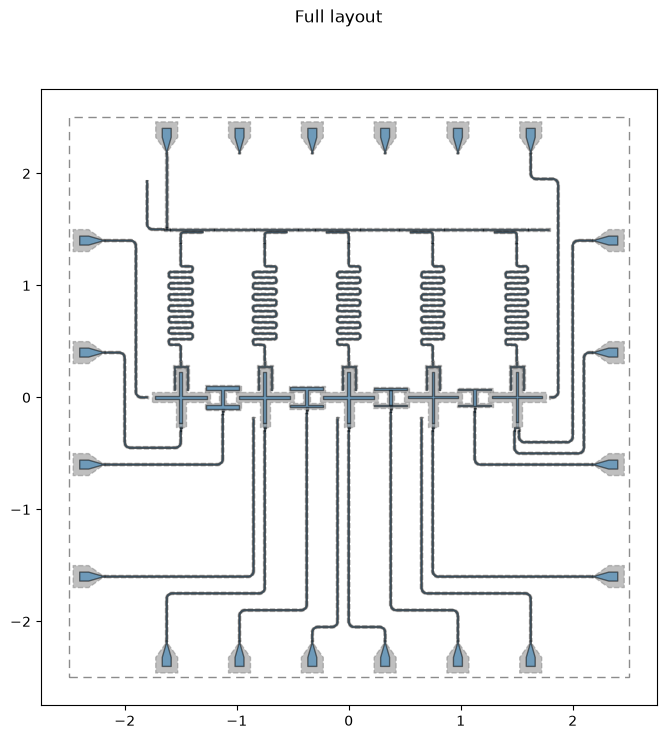

In [11]:
fig = qm.view(design)
fig.suptitle("Full layout")
fig

In [12]:
# Capacitance check (set run_capacitance_check = True in the parameters).
# Solves the islands' capacitances on the built layout with capacitance.py and
# prints the frequencies the shared junctions give with them, scaled by the
# HFSS calibration factors in the parameters. If they miss
# their targets, update the C_sigma tables in the parameters.
if run_capacitance_check:
    mid = n_qubits // 2
    probes = {
        "Q0": (qubit_x(0), qubit_row_y_mm),  # edge qubit: one coupler
        f"Q{mid}": (qubit_x(mid), qubit_row_y_mm),  # inner qubit: two couplers
        f"TC{mid - 1}": ((qubit_x(mid - 1) + qubit_x(mid)) / 2, qubit_row_y_mm),
    }
    rx, ry = design.components[f"Q{mid}"].pins["readout"].middle
    probes["claw"] = (rx, ry + 0.003)
    window = (qubit_x(0) - 0.5, qubit_x(mid) + qubit_pitch_mm * 0.9,
              qubit_row_y_mm - 0.45, qubit_row_y_mm + 0.55)
    rows = capacitance_rows(design, window, probes, pixel_um=1.5)
    for name in ("Q0", f"Q{mid}", f"TC{mid - 1}"):
        s = squids[name]
        factor = qubit_csigma_hfss_factor if name.startswith("Q") else coupler_csigma_hfss_factor
        c = rows[name][name] * factor + s["cj_ff"]  # as HFSS will see it
        f, alpha = transmon_levels(s["ej_ghz"], EC_GHZ_FF / c)
        alpha *= anharmonicity_hfss_factor
        print(f"  {name}: C_sigma {c:6.1f} fF (target {s['csigma_ff']:.1f}) -> "
              f"f_max {f:.3f} GHz (target {s['freq_ghz']:.2f}), alpha {alpha * 1e3:.0f} MHz")
    print(f"  qubit-coupler {-rows[f'Q{mid}'][f'TC{mid - 1}']:.2f} fF, "
          f"qubit-claw {-rows[f'Q{mid}']['claw']:.2f} fF")

  Q0: C_sigma  121.3 fF (target 121.8) -> f_max 4.508 GHz (target 4.50), alpha -174 MHz
  Q2: C_sigma  107.4 fF (target 106.5) -> f_max 4.779 GHz (target 4.80), alpha -198 MHz
  TC1: C_sigma  111.0 fF (target 110.8) -> f_max 5.827 GHz (target 5.83), alpha -188 MHz
  qubit-coupler 1.41 fF, qubit-claw 6.19 fF


## GDS export

In [13]:
# Each component's junction line becomes its SQUID cell: centred on the line,
# turned to point from island to ground, with this notebook's finger width and
# the line's length as the island-to-ground gap.
squid_cells = {}
for _, row in design.qgeometry.tables["junction"].iterrows():
    name = design._components[row.component].name
    squid_cells[f"SQUID_{name}"] = dict(
        finger_um=squids[name]["finger_um"], gap_um=row.geometry.length * 1e3
    )
write_squid_library(junction_gds_file, squid_cells, layer=jj_layer)

gds = design.renderers.gds
gds.options.path_filename = os.path.abspath(junction_gds_file)
gds.options.fabricate = True  # leave out the renderer's working layers
gds.options.cheese.view_in_file = Dict(main={1: False})  # no ground-plane holes
gds.options.no_cheese.view_in_file = Dict(main={1: False})
gds.export_to_gds(gds_file)

# Tidy the file for fab: one flat cell in um, with layer 1 merged (Metal splits
# it into datatype 0 for the ground plane, 10 for islands and pads, 11 for
# traces) and the SQUIDs as they are on jj_layer.
import gdstk

flat = gdstk.read_gds(gds_file).top_level()[0].flatten()
fab_lib = gdstk.Library(unit=1e-6, precision=1e-9)
chip_cell = fab_lib.new_cell("FIVE_PLUS_FOUR")
for layer, merge in ((1, True), (jj_layer, False)):
    polys = [p.scale(1e3) for p in flat.polygons if p.layer == layer]
    if merge:
        polys = gdstk.boolean(polys, [], "or", precision=1e-3, layer=layer)
    chip_cell.add(*polys)
fab_lib.write_gds(gds_file)

print(f"Wrote {gds_file} with {len(squid_cells)} SQUIDs on layer {jj_layer}:")
for cell_name, spec in squid_cells.items():
    print(f"  {cell_name:<10} finger {spec['finger_um']:.3f} um, gap {spec['gap_um']:.2f} um")


Wrote five_plus_four.gds with 9 SQUIDs on layer 2:
  SQUID_Q0   finger 0.172 um, gap 29.39 um
  SQUID_Q1   finger 0.172 um, gap 31.43 um
  SQUID_Q2   finger 0.172 um, gap 33.29 um
  SQUID_Q3   finger 0.172 um, gap 34.92 um
  SQUID_Q4   finger 0.172 um, gap 36.25 um
  SQUID_TC0  finger 0.260 um, gap 15.00 um
  SQUID_TC1  finger 0.260 um, gap 15.00 um
  SQUID_TC2  finger 0.260 um, gap 15.00 um
  SQUID_TC3  finger 0.260 um, gap 15.00 um


## HFSS simulations

Three simulations, each switched on in the parameters cell (`run_hfss_*`). All three render only part of the chip, so each finishes in a reasonable time:

* **Qubit + readout (eigenmode + EPR).** A qubit, its readout resonator and tee, and the couplers on either side. Gives each mode's frequency, the anharmonicities, and the qubit-resonator dispersive shift.
* **Qubit-coupler-qubit (eigenmode + EPR).** Two neighbouring qubits, the coupler between them, and both readouts. Gives the qubit-coupler shifts and the static ZZ between the qubits, with the coupler parked at its maximum frequency.
* **Purcell eigenmode.** The same feedline, resonators and qubits as the driven run below, with N1 as a 50 ohm resistor. Every mode's frequency and Q: the filter's own mode (lowest Q), each readout's linewidth kappa, and each qubit's Purcell-limited T1 = Q / (2 pi f).
* **Purcell readout (driven modal).** The whole feedline, all five resonators and qubits, with a 50 ohm port where N1 drops onto the line. Gives S11 as seen from N1. Each resonator shows up as a phase step and a group-delay peak; the peak's height gives its linewidth.

Each run of these cells starts a new AEDT project, so nothing is added to (or saved over) a project you already have open. It is saved next to this notebook as `hfss_project_file`, or with `_2`, `_3`, ... added if that file exists, and every simulation is a design in it. Lines that leave the rendered region (feedline ends, flux lines) are shorted to ground at the edge.

In [ ]:
# Shared by the HFSS cells below. Each junction gets its own HFSS variable
# (Lj_Q0, Lj_TC1, ...) set to the L_J from the junction cell, and a junction
# capacitance (Cj_Q0, ...), so EPR can match variables to junctions. Rebuilding the elements writes the variable names
# into the junction table; no geometry moves.
hfss_on = (run_hfss_qubit_epr or run_hfss_coupler_epr or run_hfss_full_epr
           or run_hfss_purcell_eigenmode or run_hfss_purcell)
hfss_results = {}

if hfss_on:
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    import pyEPR as epr
    from qiskit_metal.analyses.quantization import EPRanalysis
    from qiskit_metal.analyses.simulation import EigenmodeSim, ScatteringImpedanceSim

    # A new AEDT project for this run, saved at once under an unused name.
    # The renderer then attaches to it by name before every simulation, so
    # the designs cannot land in whichever project happens to be active.
    stem, ext = os.path.splitext(os.path.abspath(hfss_project_file))
    hfss_project_path, k = stem + ext, 2
    while os.path.exists(hfss_project_path):
        hfss_project_path, k = f"{stem}_{k}{ext}", k + 1
    hfss = design.renderers.hfss
    # Use AEDT 2026 R1 (2024 R2 is installed too).
    design.renderers.hfss.open_ansys(path_var="ANSYSEM_ROOT261")
    hfss.start()
    hfss.rdesktop.new_project().save(hfss_project_path)
    hfss.options.project_name = os.path.splitext(os.path.basename(hfss_project_path))[0]
    hfss.options.project_path = None
    hfss.start()  # reconnect, now to the new project
    print(f"HFSS project: {hfss_project_path} (AEDT {hfss.rdesktop.get_version()})")

    for name in squids:
        element = design.components[name]
        element.options.hfss_inductance = f"Lj_{name}"
        element.options.hfss_capacitance = f"Cj_{name}"
        element.rebuild()
    hfss_vars = Dict({f"Lj_{name}": f"{s['lj_nh']:.4f} nH" for name, s in squids.items()})
    hfss_vars.update({f"Cj_{name}": f"{s['cj_ff']:.3f} fF" for name, s in squids.items()})


def hfss_buffer(sim):
    sim.renderer.options.x_buffer_width_mm = hfss_buffer_mm
    sim.renderer.options.y_buffer_width_mm = hfss_buffer_mm


# Quantum analysis. pyEPR gets each mode's anharmonicity and the cross-Kerr
# shifts by numerically diagonalising the junction Hamiltonian in a Fock space
# of fock_trunc ** (number of modes) states, as one dense matrix: it cannot be
# interrupted, and 7 ** 5 states already takes hours. fock_trunc must still be
# 7 or more: at 5, anharmonicities come out ~20 MHz low and the ZZ ten times
# too big. So runs with more than 4 modes are diagonalised in small groups:
# each coupler with its two qubits, and each qubit with its readout. (Adding a
# readout to a coupler group changes ZZ by under 5 kHz.) Pairs of modes that
# share no group are left blank (NaN) in chi; pyEPR's first-order estimate of
# every pair is kept as chi_first_order, but it gets ZZ badly wrong.
def epr_groups(index, qubit_ids, coupler_ids):
    """Lists of mode numbers to diagonalise together, given {label: mode}."""
    if len(index) <= 4:
        return [sorted(index.values())]
    groups = [[f"Q{c}", f"TC{c}", f"Q{c + 1}"] for c in coupler_ids]
    groups += [[f"Q{i}", f"ReadoutRes{i}"] for i in qubit_ids]
    groups = [sorted(index[k] for k in g if k in index) for g in groups]
    return [g for g in groups if g]


def run_epr(sim_name, qubit_ids, coupler_ids):
    """Eigenmode + EPR of some qubits (with their readouts) and couplers.

    Returns the table of modes and the matrix of cross-Kerr shifts (MHz), and
    writes both to hfss_results_dir as CSV as soon as they exist.
    """
    elements = [f"Q{i}" for i in qubit_ids] + [f"TC{i}" for i in coupler_ids]
    readouts = [part for i in qubit_ids for part in (f"ReadoutRes{i}", f"CLT{i}")]
    n_modes = len(elements) + len(qubit_ids)  # one per element and resonator

    eig = EPRanalysis(design, "hfss")
    hfss_buffer(eig.sim)
    eig.sim.setup.update(
        n_modes=n_modes,
        min_freq_ghz=0.5 * min(min(qubit_freqs_ghz), min(coupler_freqs_ghz)),
        max_passes=hfss_max_passes,
        min_converged=hfss_min_converged,
        max_delta_f=hfss_max_delta_f,
        basis_order=hfss_basis_order,
        vars=hfss_vars,
    )
    eig.sim.run(name=sim_name, components=elements + readouts, open_terminations=[])
    eig.sim.plot_convergences()

    eig.del_junction("jj")
    for element in elements:
        eig.add_junction(
            element,
            lj_var=f"Lj_{element}",
            cj_var=f"Cj_{element}",
            rect=f"JJ_rect_Lj_{element}_rect_jj",
            line=f"JJ_Lj_{element}_rect_jj_",
        )
    # The EPR field integrals, in HFSS, written to pyEPR's data file. (Metal's
    # eig.run_epr() would follow this with one diagonalisation of every mode.)
    eig.clear_data()
    eig.get_stored_energy()
    eig.run_analysis()
    qa = epr.QuantumAnalysis(eig.sim.renderer.epr_distributed_analysis.data_filename)
    variation = qa.variations[0]

    # First order (analytic, every mode at once): enough to name the modes.
    o1 = qa.analyze_variation(variation, cos_trunc=None, fock_trunc=None, print_result=False)
    junctions = list(o1["Ljs"].index)
    f_mhz = np.real(np.asarray(o1["f_1"], dtype=complex))
    chi_o1 = np.real(np.asarray(o1["chi_O1"], dtype=complex))
    pj = np.asarray(o1["Pm_normed"], dtype=float).reshape(len(f_mhz), -1)

    # Name each mode: the junction holding most of its inductive energy, or a
    # readout resonator (in frequency order) if no junction holds much of it.
    targets = {name: squids[name]["freq_ghz"] for name in elements}
    targets.update({f"ReadoutRes{i}": resonator_freqs_ghz[i] for i in qubit_ids})
    resonators = sorted((f"ReadoutRes{i}" for i in qubit_ids), key=targets.get)
    labels = {}
    for m in np.argsort(f_mhz):
        if pj[m].max() > 0.1:
            name = junctions[int(pj[m].argmax())]
        else:
            name = resonators.pop(0) if resonators else f"mode {m}"
        if name in labels.values():
            name = f"{name} (mode {m})"
        labels[int(m)] = name
    names = [labels[m] for m in range(len(f_mhz))]
    index = {name: m for m, name in labels.items()}

    # Numerical diagonalisation, group by group (see above).
    chi_mhz = np.full_like(chi_o1, np.nan)
    for group in epr_groups(index, qubit_ids, coupler_ids):
        nd = qa.analyze_variation(
            variation,
            cos_trunc=8,
            fock_trunc=8 if len(group) <= 3 else 7,
            print_result=False,
            modes=group,
        )
        f_nd = np.real(np.asarray(nd["f_ND"], dtype=complex))
        chi_nd = np.real(np.asarray(nd["chi_ND"], dtype=complex))
        for a, m in enumerate(group):
            f_mhz[m] = f_nd[a]
            chi_mhz[m, group] = chi_nd[a]

    modes = pd.DataFrame(
        {
            "f (GHz)": f_mhz / 1e3,
            "target (GHz)": [targets.get(name, np.nan) for name in names],
            "|anharmonicity| (MHz)": np.diag(chi_mhz),
            "max junction participation": pj.max(axis=1),
        },
        index=names,
    ).sort_values("f (GHz)")
    order = modes.index
    chi = pd.DataFrame(chi_mhz, index=names, columns=names).loc[order, order]
    chi_first_order = pd.DataFrame(chi_o1, index=names, columns=names).loc[order, order]

    os.makedirs(hfss_results_dir, exist_ok=True)
    for table, kind in ((modes, "modes"), (chi, "chi"), (chi_first_order, "chi_first_order")):
        table.to_csv(os.path.join(hfss_results_dir, f"{sim_name}_{kind}.csv"))

    print(f"\n{sim_name}: modes (numerical diagonalisation)")
    print(modes.round(4).to_string())
    print("\nCross-Kerr shifts (MHz): one excitation in the row's mode shifts the")
    print("column's mode down by this much. Diagonal: the mode's own |anharmonicity|.")
    print("NaN: the two modes were not diagonalised together.")
    print(chi.round(3).to_string())
    print(f"(saved to {hfss_results_dir}/{sim_name}_*.csv)")
    return dict(modes=modes, chi=chi, chi_first_order=chi_first_order, analysis=eig)


def coupling_mhz(r, x, y):
    """Coupling g (MHz) between modes x and y of a run_epr result.

    From their cross-Kerr shift: for two coupled transmons, to lowest order,
    chi = 2 g^2 (a_x + a_y) / ((D + a_x)(D - a_y)), D = f_x - f_y, with the
    anharmonicities a negative. Valid while g << |D|.
    """
    f = r["modes"]["f (GHz)"] * 1e3
    chi = r["chi"]
    ax, ay = -chi.loc[x, x], -chi.loc[y, y]
    d = f[x] - f[y]
    return np.sqrt(abs(chi.loc[x, y] * (d + ax) * (d - ay) / (2 * (ax + ay))))


def coupler_summary_row(r, c):
    """Couplings and static ZZ around coupler c, from a run_epr result."""
    qa, tc, qb = f"Q{c}", f"TC{c}", f"Q{c + 1}"
    f = r["modes"]["f (GHz)"] * 1e3
    chi = r["chi"]
    g1, g2 = coupling_mhz(r, qa, tc), coupling_mhz(r, tc, qb)
    # Exchange between the qubits through the coupler (Yan et al. 2018). Any
    # direct qubit-qubit coupling adds to it; these runs do not separate it.
    geff = g1 * g2 / 2 * sum(1 / (f[q] - f[tc]) - 1 / (f[q] + f[tc]) for q in (qa, qb))
    detuning = f[qb] - f[qa]
    return {
        "f TC (GHz)": f[tc] / 1e3,
        "Q-Q detuning (MHz)": detuning,
        # |11> meets |02> or |20> when the detuning equals an anharmonicity.
        "detuning - |anharm.| (MHz)": min(abs(detuning) - chi.loc[q, q] for q in (qa, qb)),
        "g Qa-TC (MHz)": g1,
        "g TC-Qb (MHz)": g2,
        "g_eff via TC (MHz)": geff,
        "static ZZ (kHz)": -chi.loc[qa, qb] * 1e3,
    }


INFO 07:57PM [connect_project]: Connecting to Ansys Desktop API...
INFO 07:57PM [load_ansys_project]: 	Opened Ansys App
INFO 07:57PM [load_ansys_project]: 	Opened Ansys Desktop v2024.2.0
INFO 07:57PM [load_ansys_project]: 	Opened Ansys Project
	Folder:    c:/Users/Crow104/Desktop/Orion/qiskit_metal_tests/five_plus_four/
	Project:   five_plus_four_hfss_4
INFO 07:57PM [connect_design]: 	Opened active design
	Design:    Q1_readout_hfss [Solution type: Eigenmode]
INFO 07:57PM [get_setup]: 	Opened setup `Setup`  (<class 'pyEPR.ansys.HfssEMSetup'>)
INFO 07:57PM [connect]: 	Connected to project "five_plus_four_hfss_4" and design "Q1_readout_hfss" 😀 

INFO 07:57PM [connect_project]: Connecting to Ansys Desktop API...
INFO 07:57PM [load_ansys_project]: 	Opened Ansys App
INFO 07:57PM [load_ansys_project]: 	Opened Ansys Desktop v2024.2.0
INFO 07:57PM [load_ansys_project]: 	Opened Ansys Project
	Folder:    c:/Users/Crow104/Desktop/Orion/qiskit_metal_tests/five_plus_four/
	Project:   five_plus_four

HFSS project: c:\Users\Crow104\Desktop\Orion\qiskit_metal_tests\five_plus_four\five_plus_four_hfss_5.aedt (AEDT 2024.2.0)


INFO 07:57PM [connect_design]: 	Opened active design
	Design:    Q0_readout_hfss [Solution type: Eigenmode]
WARNING 07:57PM [connect_setup]: 	No design setup detected.
WARNING 07:57PM [connect_setup]: 	Creating eigenmode default setup.
INFO 07:57PM [get_setup]: 	Opened setup `Setup`  (<class 'pyEPR.ansys.HfssEMSetup'>)
INFO 07:57PM [get_setup]: 	Opened setup `Setup`  (<class 'pyEPR.ansys.HfssEMSetup'>)
INFO 07:57PM [analyze]: Analyzing setup Setup
07:59PM 38s INFO [get_f_convergence]: Saved convergences to c:\Users\Crow104\Desktop\Orion\qiskit_metal_tests\five_plus_four\hfss_eig_f_convergence.csv
INFO 07:59PM [__init__]: Design "Q0_readout_hfss" info:
INFO 07:59PM [__init__]: 	# eigenmodes    3
	# variations    1
INFO 07:59PM [__init__]: Design "Q0_readout_hfss" info:
INFO 07:59PM [__init__]: 	# eigenmodes    3
	# variations    1
INFO 07:59PM [do_EPR_analysis]: Variation 0  [1/1]



        energy_elec_all       = 3.18854841250051e-24
        energy_elec_substrate = 2.93294459525348e-24
        EPR of substrate = 92.0%

        energy_mag    = 4.38679363227967e-26
        energy_mag % of energy_elec_all  = 1.4%
        


INFO 07:59PM [do_EPR_analysis]: Mode 0 at 4.39 GHz   [1/3]
INFO 07:59PM [do_EPR_analysis]:     Calculating E_magnetic ...
INFO 07:59PM [do_EPR_analysis]:     Calculating E_electric ...
INFO 07:59PM [do_EPR_analysis]:      (E_E-E_H)/E_E=  98.6%   E_E=1.594e-24   E_H=2.193e-26
INFO 07:59PM [do_EPR_analysis]:     Calculating junction EPR, method=`line_voltage`
INFO 07:59PM [do_EPR_analysis]: 	junction        EPR p_0j   sign s_0j    (p_capacitive)
INFO 07:59PM [calc_p_junction]: 	Q0               0.98461  (-)        0.0143273
INFO 07:59PM [calc_p_junction]: 	TC0             0.00125411  (+)        1.20785e-05
INFO 07:59PM [calc_p_junction]: 		(U_tot_cap-U_tot_ind)/mean=0.73%
INFO 07:59PM [get_Qdielectric]: Calculating Qdielectric_main for mode 0 (0/2)
INFO 07:59PM [get_Qdielectric]: p_dielectric_main_0 = 0.9198369338709267
INFO 07:59PM [do_EPR_analysis]: Mode 1 at 5.31 GHz   [2/3]
INFO 07:59PM [do_EPR_analysis]:     Calculating E_magnetic ...
INFO 07:59PM [do_EPR_analysis]:     Calculating 

      0.99   0.0012
    0.0012     0.99
    0.0013  1.2e-05
       137    0.674    0.523
     0.674      133  0.00484
     0.523  0.00484 0.000499
    147+0j 0.673+0j 0.466+0j
  0.673+0j   141+0j0.0037+0j
  0.466+0j0.0037+0j0.000401+0j


c:\Users\Crow104\anaconda3\envs\qiskit_metal_env\Lib\site-packages\matplotlib\cbook.py:1811: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\Crow104\anaconda3\envs\qiskit_metal_env\Lib\site-packages\matplotlib\cbook.py:1408: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asanyarray(x, float)


#### Mode frequencies (MHz)

... (51 outputs left out)

###### Numerical diagonalization

0                   1                   2
Lj_Q4                                                          
9.56  0  191.71+  0.00j  1.56e-01+0.00e+00j  6.97e-01+0.00e+00j
      1    0.16+  0.00j  2.13e+02+0.00e+00j  8.04e-03+0.00e+00j
      2    0.70+  0.00j  8.04e-03+0.00e+00j  7.14e-04+0.00e+00j

c:\Users\Crow104\anaconda3\envs\qiskit_metal_env\Lib\site-packages\pandas\core\series.py:1039: ComplexWarning: Casting complex values to real discards the imaginary part
  arr = np.asarray(values, dtype=dtype)
c:\Users\Crow104\anaconda3\envs\qiskit_metal_env\Lib\site-packages\pandas\core\generic.py:1985: ComplexWarning: Casting complex values to real discards the imaginary part
  arr = np.asarray(values, dtype=dtype)



Q4_readout: modes (numerical diagonalisation)
             f (GHz)  target (GHz)  |anharmonicity| (MHz)  max junction participation
Q4            4.8222           5.1               191.7061                      0.9827
TC3           6.2689           6.5               213.2037                      0.9905
ReadoutRes4   6.8999           7.7                 0.0007                      0.0017

Cross-Kerr shifts (MHz): one excitation in the row's mode shifts the
column's mode by this much. Diagonal: the mode's own anharmonicity.
                  Q4      TC3  ReadoutRes4
Q4           191.706    0.156        0.697
TC3            0.156  213.204        0.008
ReadoutRes4    0.697    0.008        0.001

Q4: readout dispersive shift chi = 0.697 MHz (resonator shift when Q4 is excited)


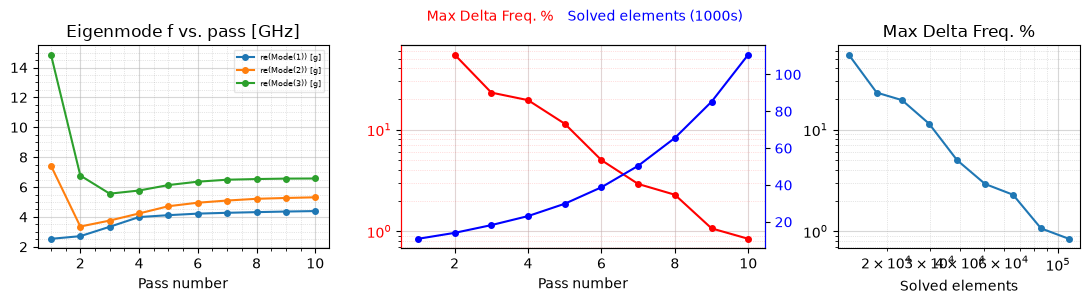

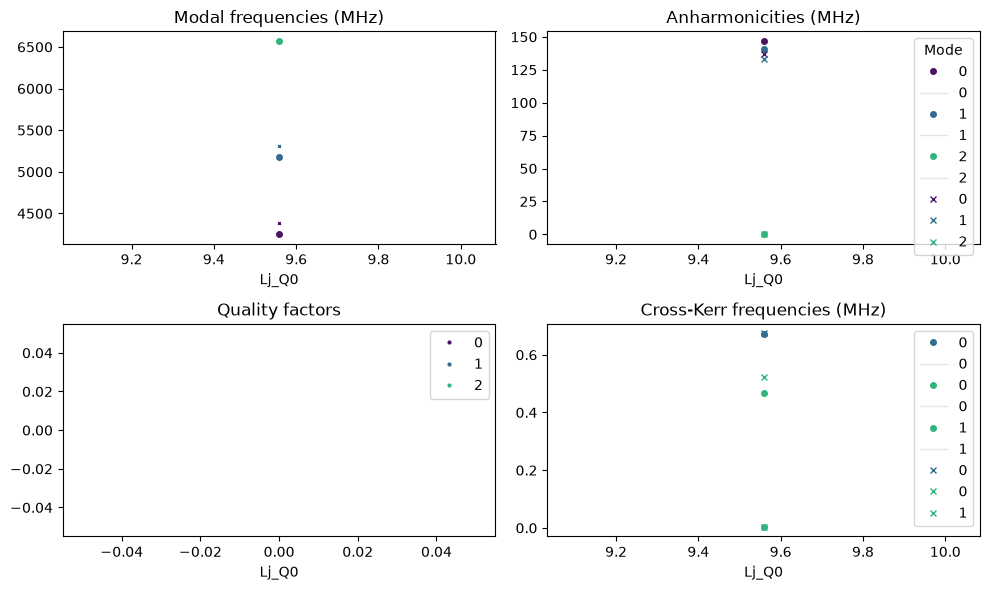

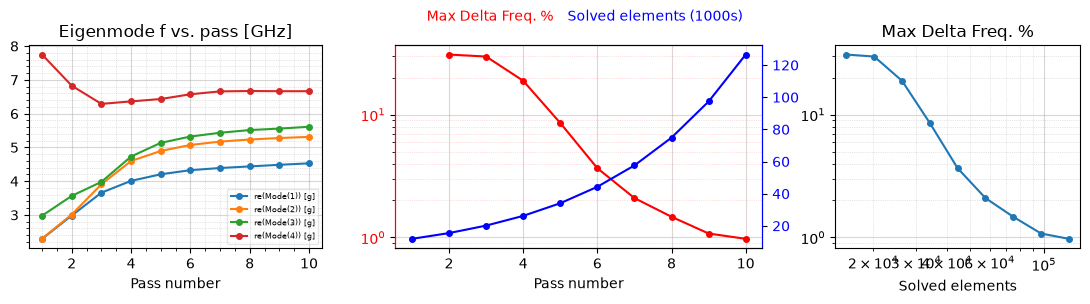

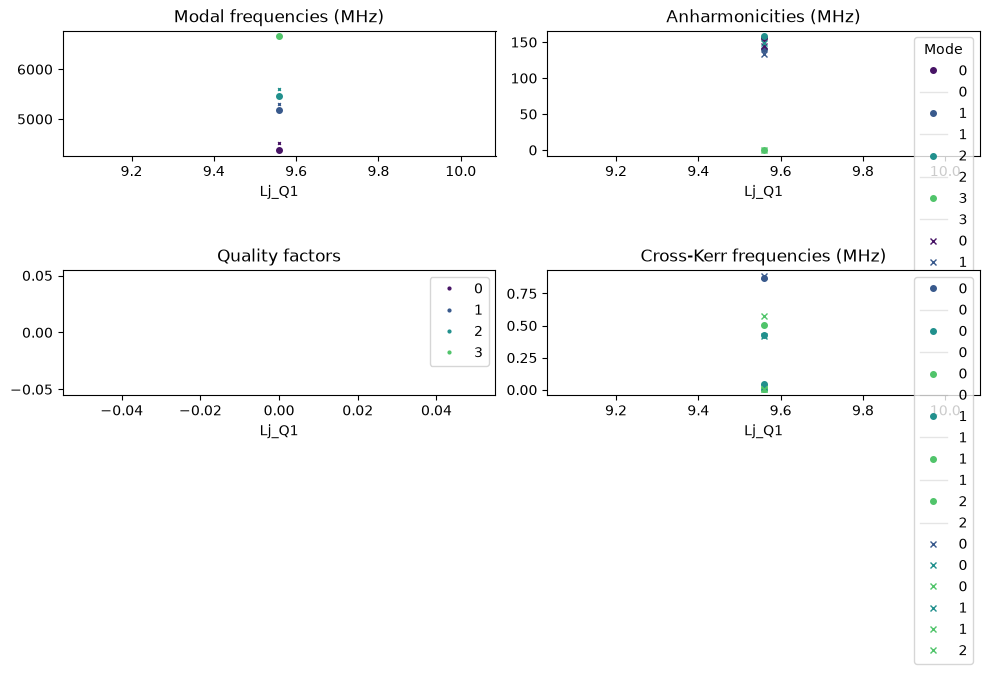

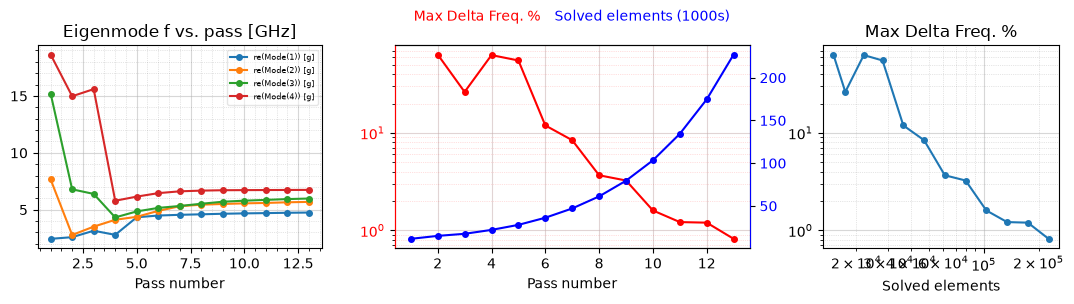

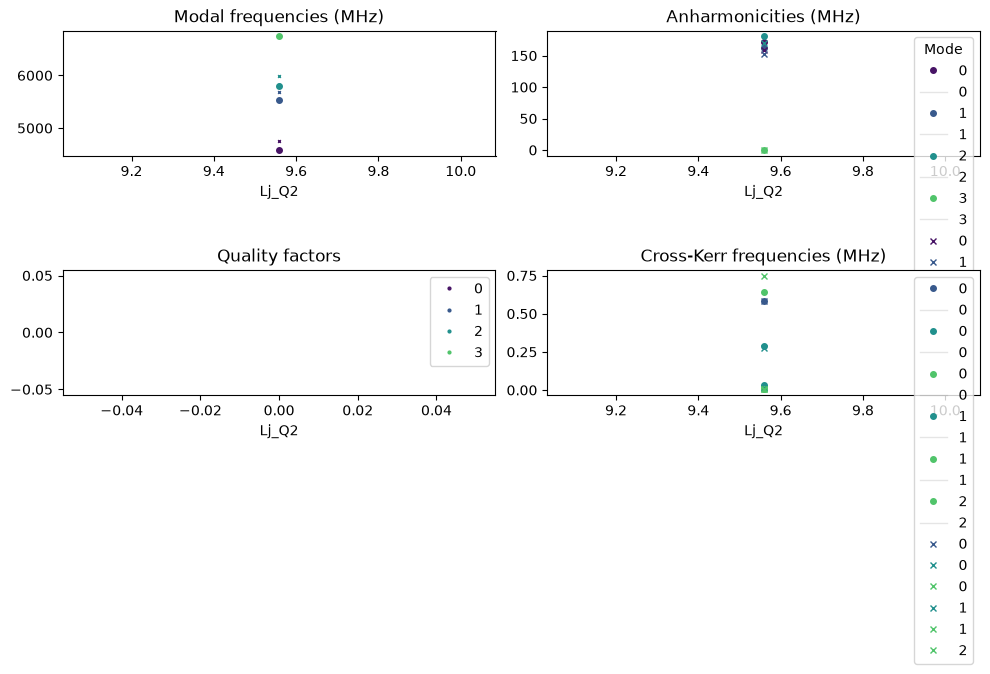

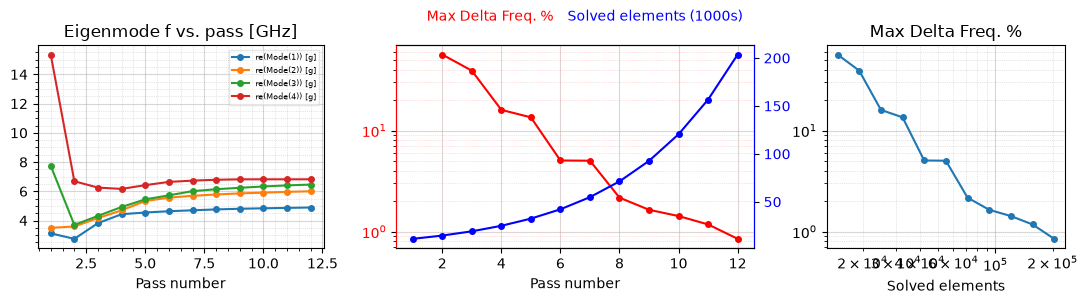

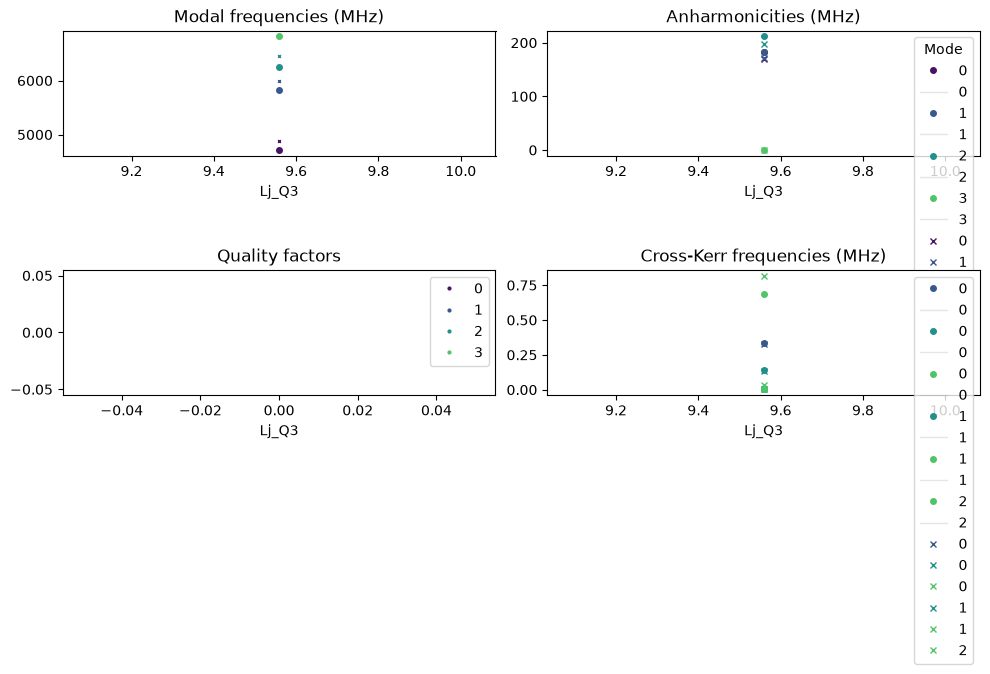

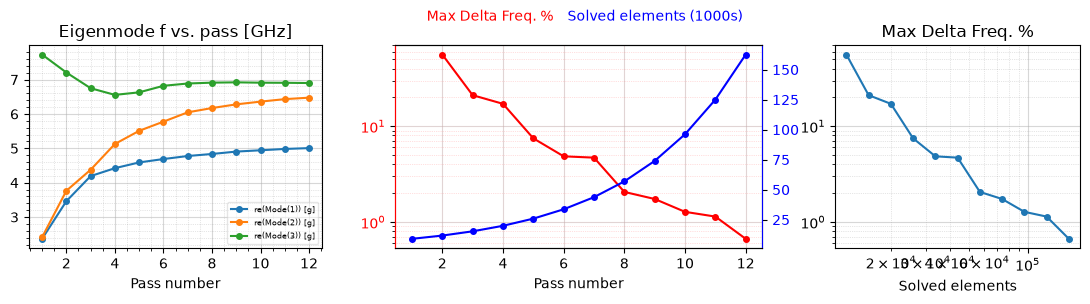

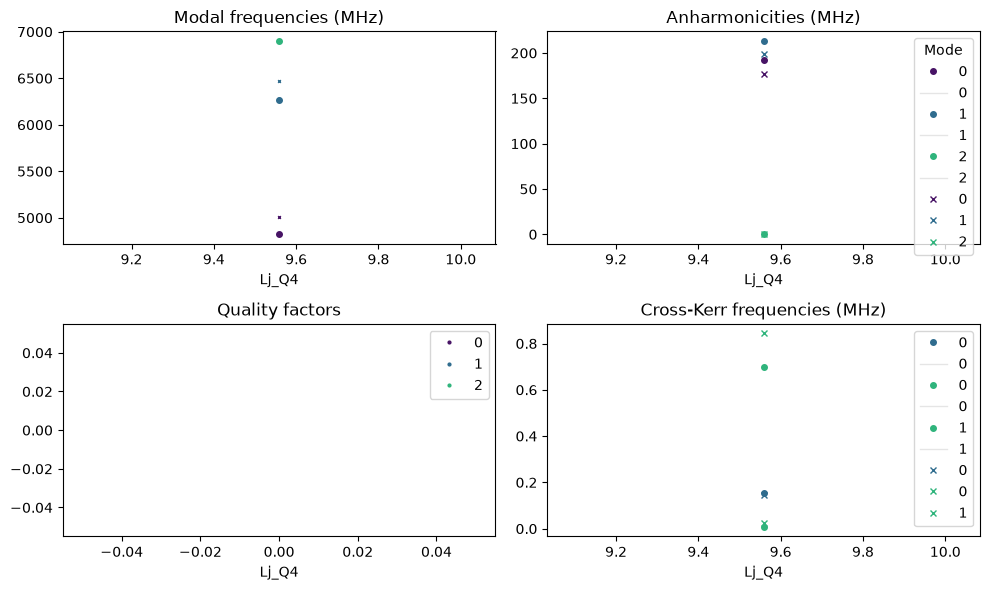

In [15]:
# Qubit + readout: a qubit, its resonator and tee, and the coupler(s) on
# either side, for each qubit in hfss_epr_qubits.
if run_hfss_qubit_epr:
    for i in hfss_epr_qubits:
        couplers = [c for c in (i - 1, i) if 0 <= c < n_qubits - 1]
        r = run_epr(f"Q{i}_readout", [i], couplers)
        chi_qr = r["chi"].loc[f"Q{i}", f"ReadoutRes{i}"]
        print(f"\nQ{i}: readout dispersive shift chi = {chi_qr:.3f} MHz "
              f"(resonator shift when Q{i} is excited)")
        hfss_results[f"Q{i}_readout"] = r

INFO 08:18PM [connect_design]: 	Opened active design
	Design:    Q1_TC1_Q2_hfss [Solution type: Eigenmode]
WARNING 08:18PM [connect_setup]: 	No design setup detected.
WARNING 08:18PM [connect_setup]: 	Creating eigenmode default setup.
INFO 08:18PM [get_setup]: 	Opened setup `Setup`  (<class 'pyEPR.ansys.HfssEMSetup'>)
INFO 08:19PM [get_setup]: 	Opened setup `Setup`  (<class 'pyEPR.ansys.HfssEMSetup'>)
INFO 08:19PM [analyze]: Analyzing setup Setup
08:24PM 29s INFO [get_f_convergence]: Saved convergences to c:\Users\Crow104\Desktop\Orion\qiskit_metal_tests\five_plus_four\hfss_eig_f_convergence.csv
INFO 08:24PM [__init__]: Design "Q1_TC1_Q2_hfss" info:
INFO 08:24PM [__init__]: 	# eigenmodes    5
	# variations    1
INFO 08:24PM [__init__]: Design "Q1_TC1_Q2_hfss" info:
INFO 08:24PM [__init__]: 	# eigenmodes    5
	# variations    1
INFO 08:24PM [do_EPR_analysis]: Variation 0  [1/1]



        energy_elec_all       = 1.3582492549846e-24
        energy_elec_substrate = 1.24926305695165e-24
        EPR of substrate = 92.0%

        energy_mag    = 1.99085952419858e-26
        energy_mag % of energy_elec_all  = 1.5%
        


INFO 08:24PM [do_EPR_analysis]: Mode 0 at 4.56 GHz   [1/5]
INFO 08:24PM [do_EPR_analysis]:     Calculating E_magnetic ...
INFO 08:24PM [do_EPR_analysis]:     Calculating E_electric ...
INFO 08:24PM [do_EPR_analysis]:      (E_E-E_H)/E_E=  98.5%   E_E=6.791e-25   E_H=9.954e-27
INFO 08:24PM [do_EPR_analysis]:     Calculating junction EPR, method=`line_voltage`
INFO 08:24PM [do_EPR_analysis]: 	junction        EPR p_0j   sign s_0j    (p_capacitive)
INFO 08:24PM [calc_p_junction]: 	Q1              0.983136  (-)        0.0154434
INFO 08:24PM [calc_p_junction]: 	Q2              6.19781e-05  (+)        9.7357e-07
INFO 08:24PM [calc_p_junction]: 	TC1             0.000763643  (+)        7.93954e-06
INFO 08:24PM [calc_p_junction]: 		(U_tot_cap-U_tot_ind)/mean=0.84%
INFO 08:24PM [get_Qdielectric]: Calculating Qdielectric_main for mode 0 (0/4)
INFO 08:24PM [get_Qdielectric]: p_dielectric_main_0 = 0.9197597954624421
INFO 08:24PM [do_EPR_analysis]: Mode 1 at 4.72 GHz   [2/5]
INFO 08:24PM [do_EPR_analy

KeyboardInterrupt: 

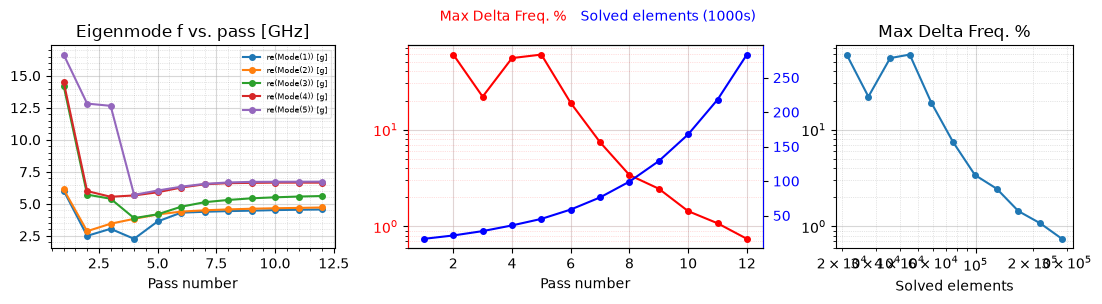

In [16]:
# Qubit-coupler-qubit: each coupler in hfss_epr_couplers with the qubits on
# either side and both their readouts. Every junction is at zero flux, so each
# coupler is at its maximum frequency and the Q-Q shift is the static ZZ there.
if run_hfss_coupler_epr:
    rows = {}
    for c in hfss_epr_couplers:
        name = f"Q{c}_TC{c}_Q{c + 1}"
        r = run_epr(name, [c, c + 1], [c])
        hfss_results[name] = r
        rows[f"TC{c}"] = coupler_summary_row(r, c)
    coupler_summary = pd.DataFrame(rows).T
    coupler_summary.to_csv(os.path.join(hfss_results_dir, "coupler_summary.csv"))
    print("\nCouplers (Qa = the lower-numbered qubit), each from its own run:")
    print(coupler_summary.round(3).to_string())


In [ ]:
# Full chip: every qubit, coupler and readout resonator (with its tee) in one
# eigenmode simulation, 14 modes. A check on the smaller runs above, with
# everything loaded at once. The slowest and most memory-hungry run (hours).
# Only neighbouring qubits are diagonalised together (see run_epr), so the
# ZZ is computed between neighbours only.
if run_hfss_full_epr:
    r = run_epr("full_chip", list(range(n_qubits)), list(range(n_qubits - 1)))
    hfss_results["full_chip"] = r
    modes, chi = r["modes"], r["chi"]
    full_qubits = pd.DataFrame(
        {
            f"Q{i}": {
                "f (GHz)": modes.loc[f"Q{i}", "f (GHz)"],
                "target (GHz)": qubit_freqs_ghz[i],
                "|anharmonicity| (MHz)": chi.loc[f"Q{i}", f"Q{i}"],
                "readout f (GHz)": modes.loc[f"ReadoutRes{i}", "f (GHz)"],
                "readout target (GHz)": resonator_freqs_ghz[i],
                "readout chi (MHz)": chi.loc[f"Q{i}", f"ReadoutRes{i}"],
            }
            for i in range(n_qubits)
        }
    ).T
    full_couplers = pd.DataFrame(
        {f"TC{c}": coupler_summary_row(r, c) for c in range(n_qubits - 1)}
    ).T
    full_qubits.to_csv(os.path.join(hfss_results_dir, "full_chip_qubits.csv"))
    full_couplers.to_csv(os.path.join(hfss_results_dir, "full_chip_couplers.csv"))
    print("\nFull chip, qubits:")
    print(full_qubits.round(4).to_string())
    print("\nFull chip, couplers (Qa = the lower-numbered qubit):")
    print(full_couplers.round(3).to_string())


In [ ]:
# Purcell eigenmode: the feedline, every readout and qubit, with N1 as a 50 ohm
# resistor (an RLC boundary where the pad's trace starts). Each mode's Q is
# then set by how much of it leaks out through N1:
#   - the filter: the lowest-Q mode near the readout band (Q ~ purcell_filter_q)
#   - each readout: kappa / 2 pi = f / Q
#   - each qubit: Purcell-limited T1 = Q / (2 pi f)
# No EPR here, so the modes are named by frequency and Q alone.
if run_hfss_purcell_eigenmode:
    feedline = ["Feed_in", "Purcell_tap", "Purcell_stub", "Purcell_short",
                "Purcell_tail", "Purcell_open"]
    feedline += [f"CLT{i}" for i in range(n_qubits)]
    feedline += [f"Feed_mid_{i}" for i in range(n_qubits - 1)]
    readout = [part for i in range(n_qubits) for part in (f"ReadoutRes{i}", f"Q{i}")]

    pe = EigenmodeSim(design, "hfss")
    hfss_buffer(pe)
    pe.setup.update(
        n_modes=2 * n_qubits + 2,  # qubits, readouts, filter, one spare
        min_freq_ghz=0.8 * min(qubit_freqs_ghz),
        max_passes=hfss_max_passes,
        min_converged=hfss_min_converged,
        max_delta_f=hfss_max_delta_f,
        basis_order=hfss_basis_order,
        vars=hfss_vars,
    )
    pe.run(
        name="Purcell_eigenmode",
        components=feedline + readout,
        open_terminations=[],
        port_list=[("Feed_in", "start", 50)],
    )
    pe.plot_convergences()

    freqs, kappas = pe.renderer.pinfo.setup.get_solutions().eigenmodes()
    f_ghz = np.asarray(freqs, dtype=float)
    k_ghz = np.asarray(kappas if kappas is not None else [np.nan] * len(f_ghz), dtype=float)
    if f_ghz.max() > 1e3:  # exported in Hz
        f_ghz, k_ghz = f_ghz / 1e9, k_ghz / 1e9
    q = f_ghz / k_ghz

    # Names: the n_qubits lowest modes are the qubits; above them the
    # lowest-Q mode is the filter; the rest are the readouts in frequency
    # order, then anything extra.
    order = list(np.argsort(f_ghz))
    labels = {m: f"Q{i}" for i, m in enumerate(order[:n_qubits])}
    rest = order[n_qubits:]
    filt = min(rest, key=lambda m: q[m])
    labels[filt] = "PurcellFilter"
    others = [m for m in rest if m != filt]
    for i, m in enumerate(others):
        labels[m] = f"ReadoutRes{i}" if i < n_qubits else f"extra{i - n_qubits}"

    targets = {f"Q{i}": f for i, f in enumerate(qubit_freqs_ghz)}
    targets.update({f"ReadoutRes{i}": f for i, f in enumerate(resonator_freqs_ghz)})
    targets["PurcellFilter"] = purcell_filter_freq_ghz
    purcell_modes = pd.DataFrame(
        {
            labels[m]: {
                "f (GHz)": f_ghz[m],
                "target (GHz)": targets.get(labels[m], np.nan),
                "Q": q[m],
                "kappa/2pi (MHz)": k_ghz[m] * 1e3,
                "Purcell T1 (us)": q[m] / (2 * np.pi * f_ghz[m] * 1e3)
                if labels[m].startswith("Q") else np.nan,
            }
            for m in order
        }
    ).T
    os.makedirs(hfss_results_dir, exist_ok=True)
    purcell_modes.to_csv(os.path.join(hfss_results_dir, "Purcell_eigenmode_modes.csv"))
    hfss_results["Purcell_eigenmode"] = purcell_modes
    print("Purcell eigenmode, N1 as 50 ohm (qubit Q and T1 converge more slowly than f):")
    print(purcell_modes.to_string(float_format=lambda v: f"{v:.4g}"))

In [ ]:
# Purcell readout: the full feedline (input tap, short stub, tees, tail and
# open end), all resonators and qubits. LP_N1 is left out so the port goes
# where the pad's trace starts. The filter is the broad phase wind of 2 pi
# (group delay 4 / kappa_filter). The readouts are steps about a MHz wide,
# so trust the eigenmode cell above for their kappa: here the mesh is only
# refined until S11 stops changing, and |S11| is 1 at every frequency (no
# loss), so the resonators can stay under-resolved.
if run_hfss_purcell:
    feedline = ["Feed_in", "Purcell_tap", "Purcell_stub", "Purcell_short",
                "Purcell_tail", "Purcell_open"]
    feedline += [f"CLT{i}" for i in range(n_qubits)]
    feedline += [f"Feed_mid_{i}" for i in range(n_qubits - 1)]
    readout = [part for i in range(n_qubits) for part in (f"ReadoutRes{i}", f"Q{i}")]

    drv = ScatteringImpedanceSim(design, "hfss")
    hfss_buffer(drv)
    start_ghz, stop_ghz, count = hfss_purcell_sweep_ghz
    drv.setup.update(
        freq_ghz=purcell_filter_freq_ghz,
        max_passes=hfss_max_passes,
        max_delta_s=hfss_max_delta_s,
        min_converged=hfss_min_converged,
        basis_order=hfss_basis_order,
        vars=hfss_vars,
    )
    drv.setup.sweep_setup.update(
        start_ghz=start_ghz, stop_ghz=stop_ghz, count=count, step_ghz=None, type="Fast"
    )
    drv.run(
        name="Purcell_readout",
        components=feedline + readout,
        open_terminations=[],
        port_list=[("Feed_in", "start", 50)],
    )

    _, _, s_params = drv.renderer.get_params(["S11"])
    f_ghz = np.asarray(s_params.index, dtype=float)
    s11 = np.asarray(s_params["S11"], dtype=complex)
    phase = np.unwrap(np.angle(s11))
    # Group delay, -d(phase)/d(omega). On resonance, a reflection off a
    # resonator peaks at 4 / kappa, so kappa / 2 pi = 2 / (pi * peak delay).
    delay_ns = -np.gradient(phase, 2 * np.pi * f_ghz)

    from scipy.signal import find_peaks

    peaks, _ = find_peaks(delay_ns, prominence=0.2 * delay_ns.max())
    print("Resonances seen from N1 (group-delay peaks):")
    for p in peaks:
        kappa_mhz = 2 / (np.pi * delay_ns[p]) * 1e3
        print(f"  {f_ghz[p]:.4f} GHz   delay {delay_ns[p]:7.1f} ns   kappa/2pi ~ {kappa_mhz:.2f} MHz")
    print(f"Targets: resonators {resonator_freqs_ghz} GHz, "
          f"filter {purcell_filter_freq_ghz} GHz (Q ~ {purcell_filter_q})")

    fig, axs = plt.subplots(3, 1, figsize=(9, 8), sharex=True)
    axs[0].plot(f_ghz, 20 * np.log10(np.abs(s11)))
    axs[0].set_ylabel("|S11| (dB)")
    axs[1].plot(f_ghz, phase)
    axs[1].set_ylabel("phase (rad)")
    axs[2].plot(f_ghz, delay_ns)
    axs[2].plot(f_ghz[peaks], delay_ns[peaks], "x")
    axs[2].set_ylabel("group delay (ns)")
    axs[2].set_xlabel("frequency (GHz)")
    for f in resonator_freqs_ghz:
        for ax in axs:
            ax.axvline(f, color="grey", lw=0.5, ls=":")
    fig.suptitle("S11 at N1 (dotted: target resonator frequencies)")
    fig.tight_layout()
    hfss_results["Purcell_readout"] = dict(f_ghz=f_ghz, s11=s11, peaks_ghz=f_ghz[peaks])

In [ ]:
# Save the AEDT project (every simulation above is a design in it) and
# release the connection to AEDT. AEDT itself stays open for inspection.
if hfss_on:
    hfss.pinfo.project.save()
    print(f"Saved the HFSS project to {hfss_project_path}")
    hfss.stop()